<a href="https://colab.research.google.com/github/brenaSF/ddfre-churn-prediction/blob/main/DDRFRE_eda_modelagem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Tarefa 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency


In [61]:
data_clientes = pd.read_csv("sample_data/BankCustomerChurnPrediction.csv")


In [62]:
data_clientes.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


- customer_id pode ser retirado da base ou anonimizado
- credit score pode ter alta relevancia em relação a variável churn ( hipótese ), pois quanto maior um score de um cliente, maior chance de ele realizar mais compras e se manter utilizando um serviço.
- clientes mais jovens podem ter uma alta taxa de cancelamento do serviço
- clientes com maior tenure ( tempo de permanência) no serviço, tende a permanecer utilizando o serviço
- clientes com mais cartões de crédito tendem a permanecer no serviço
- clientes com um salário maior tender a permancer no serviço.
- país não é importante a principio

In [63]:
data_clientes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [64]:
data_clientes.isnull().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


In [65]:
data_clientes.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


A média entre tempo de permanencia é 5 anos

In [66]:
# dados duplicados

data_clientes.duplicated().sum()

np.int64(0)

# EDA

In [67]:

clientes = data_clientes['churn'].value_counts()

clientes

,count
churn,
0,7963
1,2037


In [68]:
clientes.index

Index([0, 1], dtype='int64', name='churn')

In [69]:
clientes.values

array([7963, 2037])

/tmp/ipykernel_5573/2098468780.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels( ['Não churn','Churn'])


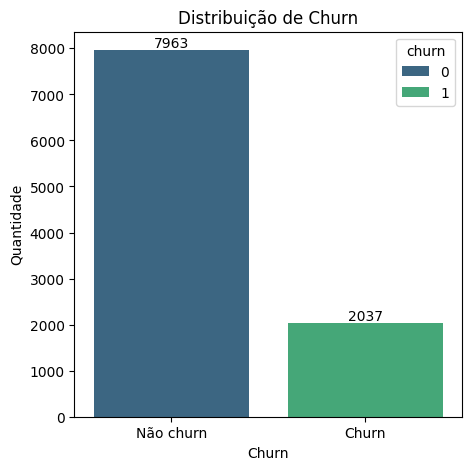

In [70]:

fig,ax = plt.subplots(figsize=(5,5))
ax = sns.countplot(data = data_clientes,x = 'churn', palette='viridis', hue='churn')
plt.xlabel('Churn')
plt.ylabel('Quantidade')
plt.title('Distribuição de Churn')
ax.set_xticklabels( ['Não churn','Churn'])

for i, v in enumerate(clientes.values):
    ax.text(i, v, str(v), ha='center', va='bottom')

plt.show()

quantidade de amostras de churn e não churn está desequilibrada, necessário aplicação de técnica de balanceamento - exemplos oversampling, undersampling , híbrida

In [71]:
data_clientes['country'].value_counts()

,count
country,
France,5014
Germany,2509
Spain,2477


/tmp/ipykernel_5573/161267088.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Mulheres','Homens'])


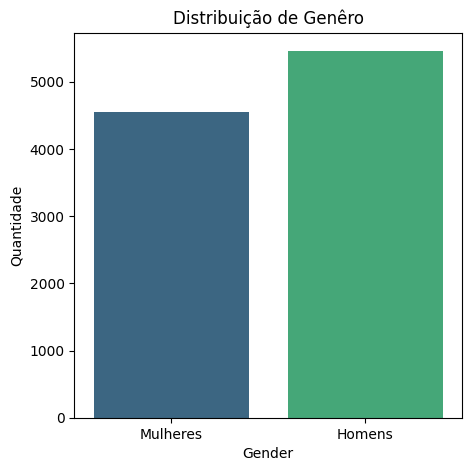

In [72]:
# correlacao com valores numéricos
fig.ax = plt.subplots(figsize=(5,5))
ax = sns.countplot(data = data_clientes, x ='gender', palette = 'viridis', hue='gender')
plt.xlabel('Gender')
plt.ylabel('Quantidade')
plt.title('Distribuição de Genêro')

ax.set_xticklabels(['Mulheres','Homens'])

plt.show()

In [73]:
data_clientes['gender'].value_counts()*100/len(data_clientes) # valor total por genero

,count
gender,
Male,54.57
Female,45.43


In [74]:
# quantidade de mulhures e homens que foram Churn ou não no período

churn_gender = data_clientes['gender'].groupby(data_clientes['churn']).value_counts()

churn_gender

churn  gender
0      Male      4559
       Female    3404
1      Female    1139
       Male       898
Name: count, dtype: int64

In [75]:
pd.crosstab(data_clientes['churn'], data_clientes['gender'])

gender,Female,Male
churn,,
0,3404,4559
1,1139,898


NameError: name 'w' is not defined

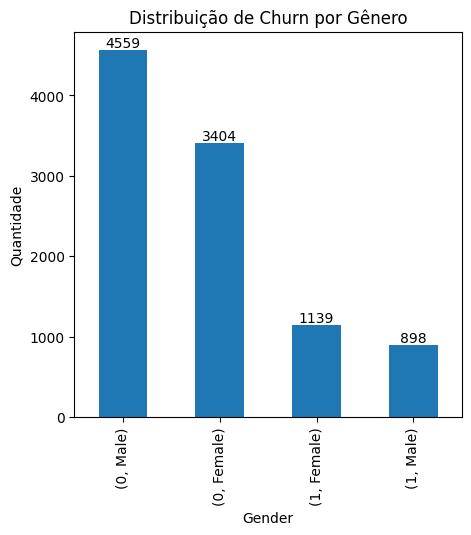

In [76]:
fig, ax = plt.subplots(figsize=(5,5))

churn_gender.plot(x='gender', y='quantidade', kind='bar', legend=False)

plt.xlabel('Gender')
plt.ylabel('Quantidade')
plt.title('Distribuição de Churn por Gênero')

for i, v in enumerate(churn_gender.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
w
ax.set_xticklabels(['Homens não churn','Mulheres não churn','Mulheres churn','Homens churn'])
plt.show()

In [ ]:

#churn = 1

churn_gender_1 = pd.crosstab(data_clientes['churn'], data_clientes['gender'], normalize='index')*100
churn_gender_1 = churn_gender_1.loc[1]


fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    churn_gender_1,
    labels=churn_gender_1.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#e74c3c', '#3498db'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
ax.set_title('Composição por Gênero entre Clientes Churn (Total = 100% dos Churns)')
plt.tight_layout()
plt.show()

Existem mais homens na base de dados do que mulheres, homes correspondem a 54,57% da base (5457) e ,mulheres correspondem a 45,43%(4543)

/tmp/ipykernel_5573/2023572757.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x = 'churn',y = 'credit_score', data = data_clientes,   palette=['skyblue', 'salmon'] )


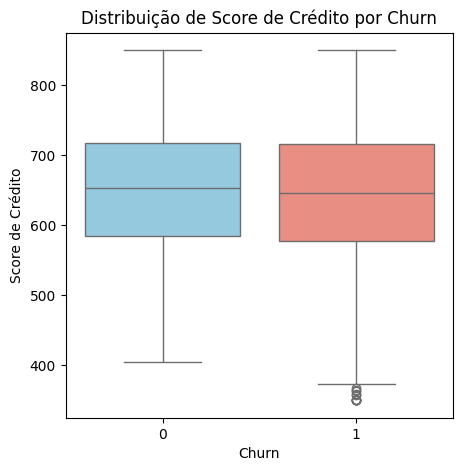

In [77]:
figure,ax = plt.subplots(figsize=(5,5))
ax = sns.boxplot(x = 'churn',y = 'credit_score', data = data_clientes,   palette=['skyblue', 'salmon'] )
plt.xlabel('Churn')
plt.ylabel('Score de Crédito')
plt.title('Distribuição de Score de Crédito por Churn')
plt.show()

Sobre o gráfico : A média entre os clientes que não cancelaram o serviço com o banco é quase a mesma da média de score de crédito de quem cancelou. Existem alguns outliers que mostram que clientes que clientes com score abaixo de 400 cancelaram o serviço com o banco

Análise detalhada : Assim, ter score de crédito alto ou baixo não é uma variável de correlação para que o cliente permaneça ou não com o serviço

Próximos passos : Nada

## Tabela de contigência para gênero


In [78]:
import pandas as pd
from scipy.stats import chi2_contingency

# 1. Tabela de contingência com frequências absolutas (entrada obrigatória para o teste)
tabela_abs = pd.crosstab(data_clientes['gender'], data_clientes['churn'])

# 2. Taxa percentual de churn dentro de cada gênero (soma 100% na horizontal / por linha)
taxa_churn_genero = pd.crosstab(
    data_clientes['gender'],
    data_clientes['churn'],
    normalize='index'
) * 100

print("--- Contagem Absoluta ---")
print(tabela_abs)
print("\n--- Taxa de Churn por Gênero (%) ---")
print(taxa_churn_genero.round(2))

# 3. Teste Qui-quadrado de independência
chi2, p_valor, gl, freq_esperadas = chi2_contingency(tabela_abs)

print(f"\nEstatística Qui-quadrado (χ²): {chi2:.4f}")
print(f"Graus de liberdade: {gl}")
print(f"Valor-p (p-value): {p_valor:.4e}")

# 4. Decisão estatística (nível de significância alfa = 0.05)
alpha = 0.05
if p_valor < alpha:
    print("Resultado: Diferença estatisticamente significativa (rejeita H0 — gênero e churn são dependentes).")
else:
    print("Resultado: Diferença NÃO significativa (falha em rejeitar H0 — variação pode ser ao acaso).")

--- Contagem Absoluta ---
churn      0     1
gender            
Female  3404  1139
Male    4559   898

--- Taxa de Churn por Gênero (%) ---
churn       0      1
gender              
Female  74.93  25.07
Male    83.54  16.46

Estatística Qui-quadrado (χ²): 112.9186
Graus de liberdade: 1
Valor-p (p-value): 2.2482e-26
Resultado: Diferença estatisticamente significativa (rejeita H0 — gênero e churn são dependentes).


/tmp/ipykernel_5573/3106161025.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_clientes,x='estimated_salary',palette='viridis')


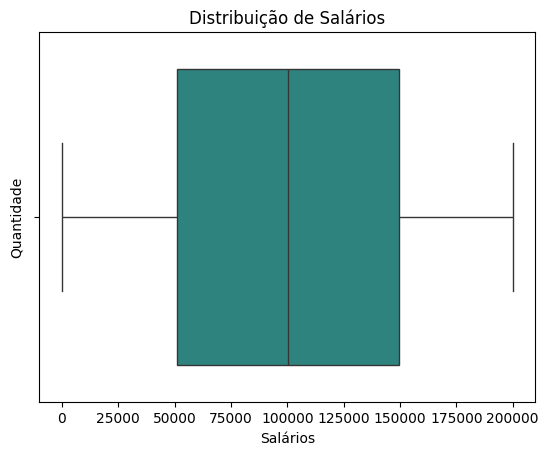

In [79]:
# verificar os salários dos clientes com boxplot

sns.boxplot(data=data_clientes,x='estimated_salary',palette='viridis')

plt.title('Distribuição de Salários')
plt.xlabel('Salários')
plt.ylabel('Quantidade')
plt.show()

Os

In [82]:
# agrupar por idades (age) em grupos de faixa etária

data_clientes['age_group'] = pd.cut(
    data_clientes['age'],
    bins=[17, 25, 35, 50, 65, 100]
)

data_clientes['age_group']

,age_group
0,"(35, 50]"
1,"(35, 50]"
2,"(35, 50]"
3,"(35, 50]"
4,"(35, 50]"
...,...
9995,"(35, 50]"
9996,"(25, 35]"
9997,"(35, 50]"
9998,"(35, 50]"


In [89]:
from scipy.stats import mannwhitneyu

res = mannwhitneyu(data_clientes.loc[data_clientes.churn==1,'age'], data_clientes.loc[data_clientes.churn==0,'age'], method='asymptotic')

res

MannwhitneyuResult(statistic=np.float64(11874649.5), pvalue=np.float64(3.2104014319371675e-230))

/tmp/ipykernel_5573/3170015342.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data_clientes, x='age_group', palette='viridis')


<Axes: xlabel='age_group', ylabel='count'>

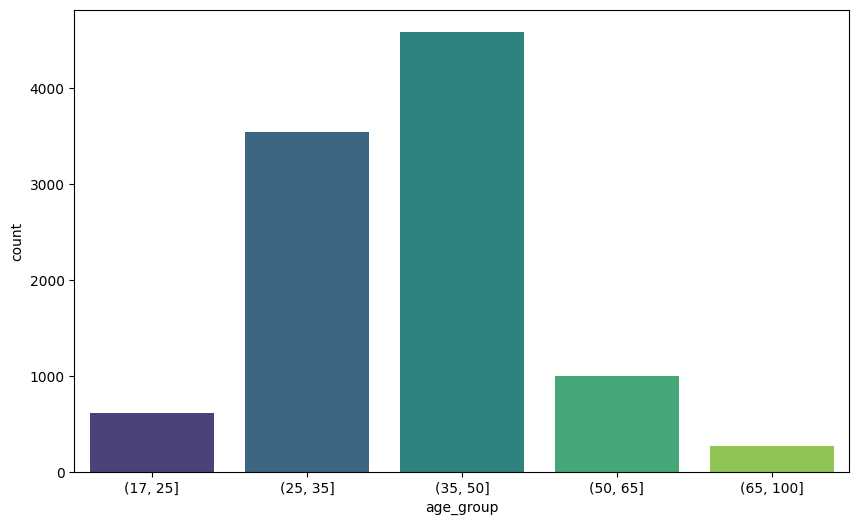

In [83]:
# gerar grafico de frquencia das faixas etarias

plt.figure(figsize=(10, 6))
sns.countplot(data=data_clientes, x='age_group', palette='viridis')

In [41]:
data_clientes.drop(columns='customer_id', inplace=True) # excluir id de cliente, pois não interfere na análise exploratória

KeyError: "['customer_id'] not found in axis"

In [57]:
data_clientes.drop(columns='age',inplace=True)

In [31]:
select_number_variable = data_clientes.select_dtypes(include=['int64','float64'])

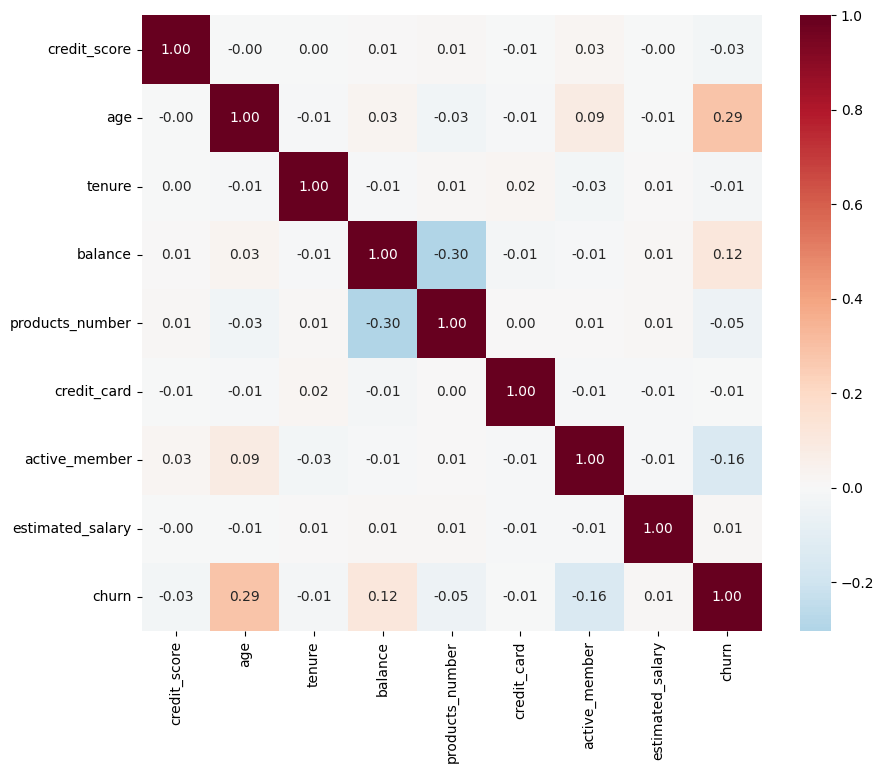

In [32]:
# heatmap com variáveis numéricas


plt.figure(figsize=(10, 8))
sns.heatmap(select_number_variable.corr(),fmt='.2f', annot=True, cmap='RdBu_r',center=0)
plt.show()

## Análise bivariada

Examinar a associação, a variação e a correlação entre duas variáveis

Teste qui-quadrado - variáveis categóricas
- Se (p < 0.05): alta relação entre as variáveis
- Se (p >= 0.05) : baixa relação entre as variáveis

In [59]:
data_clientes.head()

,credit_score,country,gender,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,age_group
0,619,France,Female,2,0.00,1,1,1,101348.88,1,36-50
1,608,Spain,Female,1,83807.86,1,0,1,112542.58,0,36-50
2,502,France,Female,8,159660.80,3,1,0,113931.57,1,36-50
3,699,France,Female,1,0.00,2,0,0,93826.63,0,36-50
4,850,Spain,Female,2,125510.82,1,1,1,79084.10,0,36-50


In [84]:
tipos = [
    'country',
    'gender',
    'age_group',
    'tenure',
    'products_number',
    'active_member',

]

def analise_bivariada (coluna_1, coluna_2):
    tabela = pd.crosstab(data_clientes[coluna_1], data_clientes[coluna_2])

    chi2, p_valor, gl, freq_esperadas = chi2_contingency(tabela)

    print(f"\nEstatística Qui-quadrado (χ²): {chi2:.4f}")
    print(f"Graus de liberdade: {gl}")
    print(f"Valor-p (p-value): {p_valor:.4e}")

    alpha = 0.05
    if p_valor < alpha:
        print(f"Resultado: Diferença estatisticamente significativa (rejeita H0 — {coluna_1} e churn são dependentes).")
    else:
        print(f"Resultado: Diferença NÃO significativa (falha em rejeitar H0 — variação - {coluna_1} pode ser ao acaso).")


for i in range(len(tipos)):
    analise_bivariada(tipos[i], 'churn')




Estatística Qui-quadrado (χ²): 301.2553
Graus de liberdade: 2
Valor-p (p-value): 3.8303e-66
Resultado: Diferença estatisticamente significativa (rejeita H0 — country e churn são dependentes).

Estatística Qui-quadrado (χ²): 112.9186
Graus de liberdade: 1
Valor-p (p-value): 2.2482e-26
Resultado: Diferença estatisticamente significativa (rejeita H0 — gender e churn são dependentes).

Estatística Qui-quadrado (χ²): 1080.8844
Graus de liberdade: 4
Valor-p (p-value): 1.0532e-232
Resultado: Diferença estatisticamente significativa (rejeita H0 — age_group e churn são dependentes).

Estatística Qui-quadrado (χ²): 13.9004
Graus de liberdade: 10
Valor-p (p-value): 1.7758e-01
Resultado: Diferença NÃO significativa (falha em rejeitar H0 — variação - tenure pode ser ao acaso).

Estatística Qui-quadrado (χ²): 1503.6294
Graus de liberdade: 3
Valor-p (p-value): 0.0000e+00
Resultado: Diferença estatisticamente significativa (rejeita H0 — products_number e churn são dependentes).

Estatística Qui-quadr

Analisando o qui-quadrado que calcula o valor de p-value, verifica-se que credit_card, tenure e estimated_salary não tão tanta correlação no processo de churn.

# Encode de variáveis categóricas  e normalização de variáveis numéricas

In [ ]:
# categóricas

data_clientes = pd.get_dummies(
    data_clientes,
    columns=['country', 'gender'],
    drop_first=True,
    dtype=int  # Garante 0 e 1 em vez de True e False
)


In [ ]:
data_clientes.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [ ]:
# numéricas - standardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

data_clientes[['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']] = scaler.fit_transform(data_clientes[['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']])

In [ ]:
data_clientes.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
0,-0.326221,0.293517,-1.041760,-1.225848,-0.911583,1,1,0.021886,1,0,0,0
1,-0.440036,0.198164,-1.387538,0.117350,-0.911583,0,1,0.216534,0,0,1,0
2,-1.536794,0.293517,1.032908,1.333053,2.527057,1,0,0.240687,1,0,0,0
3,0.501521,0.007457,-1.387538,-1.225848,0.807737,0,0,-0.108918,0,0,0,0
4,2.063884,0.388871,-1.041760,0.785728,-0.911583,1,1,-0.365276,0,0,1,0


# Modelo de dados - Random Forest

In [ ]:
# random forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = data_clientes.drop('churn', axis=1)
y = data_clientes['churn']



In [ ]:
# dividir dados de teste e treinamento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

RandomForestClassifier()

In [ ]:
y_pred = rf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred)

metrics = {
    "Accuracy":  round(accuracy_score(y_test, y_pred),  4),
    "Precision": round(precision_score(y_test, y_pred), 4),
    "Recall":    round(recall_score(y_test, y_pred),    4),
    "F1-Score":  round(f1_score(y_test, y_pred),        4),
    "ROC-AUC":   round(roc_auc_score(y_test, y_pred),   4),
}

metrics_df = pd.DataFrame.from_dict(metrics, orient="index", columns=["Score"])
print("--- Model Evaluation Metrics ---")
display(metrics_df)

--- Model Evaluation Metrics ---


,Score
Accuracy,0.8685
Precision,0.7642
Recall,0.4784
F1-Score,0.5884
ROC-AUC,0.7211


Mesmo com uma acurácia alta para o modelo de 86,8%, o modelo tem um recall baixo de 47,8%, mostrando que pode errar ao não considerar clientes com churn. Além disso, o F1-score também é baixo, cerca de 58,8%. Neste caso, é necessário tirar as variáveis que mostraram um valor de qui-quadrado que não excluí a hipótese nula(H0) para a variável, ou seja, quando variáveis não tem nenhuma relação com churn.

Próximos passos - fazer tratamento em cima destas variáveis e retirar do treinamento a fim de melhorar o valor de recall

# Modelo de dados - Xboost

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xb = XGBClassifier()
xb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred_xb = xb.predict(X_test)

In [ ]:
metricas_xb = {
    "Accuracy":  round(accuracy_score(y_test, y_pred_xb),  4),
    "Precision": round(precision_score(y_test, y_pred_xb), 4),
    "Recall":    round(recall_score(y_test, y_pred_xb),    4),
    "F1-Score":  round(f1_score(y_test, y_pred_xb),        4),
    "ROC-AUC":   round(roc_auc_score(y_test, y_pred_xb),   4),
}

metricas_xb_df = pd.DataFrame.from_dict(metricas_xb, orient="index", columns=["Score"])
print("--- Model Evaluation Metrics ---")
display(metricas_xb_df)

--- Model Evaluation Metrics ---


,Score
Accuracy,0.8630
Precision,0.7003
Recall,0.5293
F1-Score,0.6029
ROC-AUC,0.7369


O trainamento da base de dados com o modelo Xboost mostrou melhoria no recall e f1-score para predição de churn de clientes, os valores de recall e f1 são respectivamente, 52,9% e 60,3%. A acurácia e precisão caíram um pouco em relação ao modelo random forest, de 86,8% para 86,3% (acurácia) e 76,4% para 70,0% (precisão).

O modelo ficou mais sensível na classificação de possíveis clientes churn, o que pode gerar o alerta para os analistas.  No entanto, a acurácia e precisão sofreram neste processo, o que é bom para gerar maior engajamento de clientes, mas se mostram mais eficientes se o retorno financeiro dos clientes salvos supere o custo dos alarmes falsos.

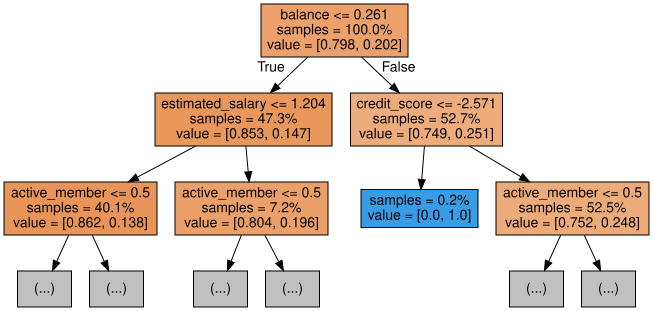

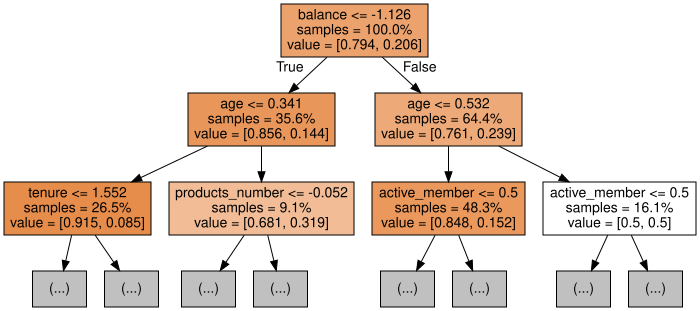

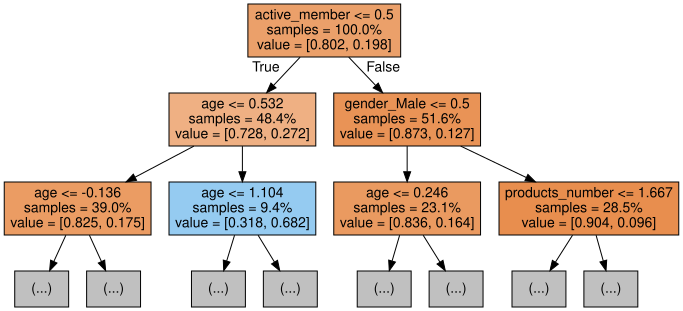

In [ ]:
import graphviz
from sklearn.tree import export_graphviz

for i in range(3):
    tree = rf.estimators_[i]
    dot_data = export_graphviz(tree,
                               feature_names=X_train.columns,
                               filled=True,
                               max_depth=2
                               impurity=False,
                               proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)

# Análise do modelo - Random Forest

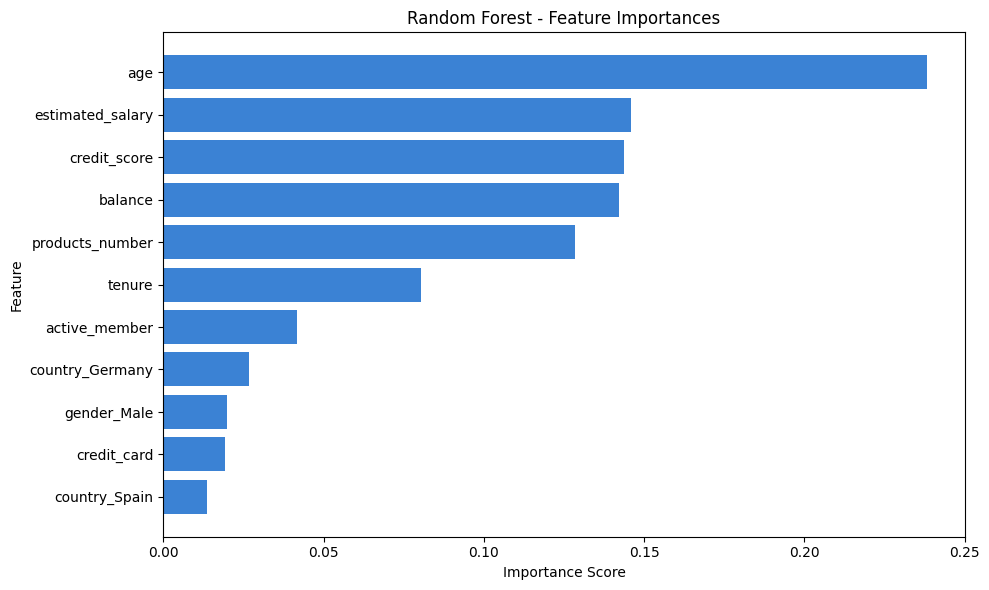

In [ ]:
import matplotlib.pyplot as plt

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp_df = importances.reset_index()
imp_df.columns = ["Feature", "Importance"]

plt.figure(figsize=(10, 6))
plt.barh(imp_df['Feature'], imp_df['Importance'], color='#3b82d4')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()